# Backtracking line search + Barzilai–Borwein

## Постановка задачи

Backtracking line search + Barzilai–Borwein. Реализовать градиентный спуск, в котором длина шага не задаётся одной константой: сначала оценивать шаг по правилу Barzilai–Borwein на основе изменений параметров и градиентов между двумя последними итерациями, а затем при необходимости уменьшать его с помощью backtracking line search до выполнения условия достаточного уменьшения функции. Сравнить с обычным градиентным спуском с фиксированным learning rate на квадратичной функции из семинара и показать графики значения функции и длины шага по итерациям.

Будем рассматривать на вытянутой квадратичной функции:

$$
L(w_1,w_2)=50w_1^2+w_2^2\qquad
\nabla L(w)=\begin{pmatrix}100w_1 \\ 2w_2\end{pmatrix}
$$

Гессиан функции равен $H=\operatorname{diag}(100,2)$, а глобальный минимум в точке $(0,0)$. Для обоих методов используем одинаковую начальную точку $w_0=(2,2)$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

from plots.optimization import (
    plot_objective_history,
    plot_step_history,
    plot_trajectories,
)
from utils.quadratic import (
    MINIMUM_POINT,
    START_POINT,
    quadratic_gradient,
    quadratic_value,
)

IMAGE_DIR = Path("images")
ITERATIONS = 100
EPS = 1e-10

BASELINE_LEARNING_RATE = 0.01
BB_INITIAL_STEP = 0.05

ARMIJO_CONSTANT = 1e-4
BACKTRACKING_CONSTANT = 0.5

## Baseline

$$w_{k+1}=w_k-\eta\nabla L(w_k)$$

Используем $\alpha_k=\eta$.

У такого подхода имеются проблемы:

- при слишком большой $\eta$ перескакиваем через оптимум
- при слишком маленьком $\eta$ движение очень медленное вдоль пологого направления

В качестве baseline используем шаг $\eta=0.01$ (он устойчивый, ведь $0.01 < \frac{2}{100}$). Сохраняем точку, значение функции, норму градиента и длину шага.

In [2]:
def baseline_gradient(get_value, gradient, x0, learning_rate):
    point = x0.copy()
    points = [point.copy()]
    values = [get_value(point)]
    gradient_norms = [np.linalg.norm(gradient(point))]
    step_sizes = []

    for _ in range(ITERATIONS):
        grad = gradient(point)
        if np.linalg.norm(grad) <= EPS:
            break

        point = point - learning_rate * grad
        
        points.append(point.copy())
        values.append(get_value(point))
        gradient_norms.append(np.linalg.norm(gradient(point)))
        step_sizes.append(learning_rate)

    return {
        "points": np.asarray(points),
        "values": np.asarray(values),
        "gradient_norms": np.asarray(gradient_norms),
        "step_sizes": np.asarray(step_sizes),
    }

## Оптимизации

### 1. Barzilai–Borwein

После перехода из $w_{k-1}$ в $w_k$ известны изменения параметров и градиентов:

$$s_{k-1}=w_k-w_{k-1}\qquad y_{k-1}=\nabla L(w_k)-\nabla L(w_{k-1})$$

$$\alpha_k=\frac{s_{k-1}^Ts_{k-1}}{s_{k-1}^Ty_{k-1}}$$

Формулу можно интерпретировать как скалярную оценку обратной кривизны. На первой итерации $s, y$ ещё нет, поэтому используем начальное значение $\alpha_0=0.05$ (специально выбрано не самое лучшее, чтобы было совершенно побольше операций и графики были побольше, а также чтобы мы не достигали минимума).

### 2. Backtracking line search

Шаг после Barzilai–Borwein может оказаться слишком большим, поэтому проверим условие Армихо:

$$L(w_k-\alpha_k\nabla L(w_k))\leq L(w_k)-c\alpha_k\|\nabla L(w_k)\|_2^2$$

Пока условие не верно делим $\alpha_k$ пополам. Таким образом, Barzilai–Borwein позволяет делать выводы о размере шага, за счёт кривизны, а backtracking проверяет, что мы достаточно уменьшились.

In [3]:
def barzilai_borwein_prev_step(point, previous_point, grad, previous_grad):
    if previous_point is None:
        return BB_INITIAL_STEP

    parameter_delta = point - previous_point
    gradient_delta = grad - previous_grad
    return (parameter_delta @ parameter_delta) / (
        parameter_delta @ gradient_delta
    )


def backtracking_line_search(get_value, point, value, grad, candidate_step):
    step = candidate_step
    new_point = point - step * grad
    new_value = get_value(new_point)
    while new_value > value - ARMIJO_CONSTANT * step * (grad @ grad):
        step *= BACKTRACKING_CONSTANT
        new_point = point - step * grad
        new_value = get_value(new_point)

    return step, new_point, new_value


def bb_backtracking_gradient(get_value, gradient, x0):
    point = x0.copy()
    value = get_value(point)
    grad = gradient(point)

    points = [point.copy()]
    values = [value]
    gradient_norms = [np.linalg.norm(grad)]
    step_sizes = []
    candidate_steps = []

    previous_point = None
    previous_grad = None

    for _ in range(ITERATIONS):
        grad_norm = np.linalg.norm(grad)
        if grad_norm <= EPS:
            break

        candidate_step = barzilai_borwein_prev_step(
            point, previous_point, grad, previous_grad
        )
        step, new_point, new_value = backtracking_line_search(
            get_value, point, value, grad, candidate_step
        )

        previous_point, previous_grad = point.copy(), grad.copy()
        point, value = new_point, new_value
        grad = gradient(point)

        points.append(point.copy())
        values.append(value)
        gradient_norms.append(np.linalg.norm(grad))
        candidate_steps.append(candidate_step)
        step_sizes.append(step)

    return {
        "points": np.asarray(points),
        "values": np.asarray(values),
        "gradient_norms": np.asarray(gradient_norms),
        "step_sizes": np.asarray(step_sizes),
        "candidate_steps": np.asarray(candidate_steps),
    }

## Эксперимент

Оба метода запускаются из точки $(2,2)$, совершают не более 50 итераций и критерий остановки $\|\nabla L(w_k)\|_2\leq10^{-10}$

 Алгосы отличаются только выбором шага:

- baseline всегда использует $0.01$;
- адаптивный метод начинает с $0.05$, затем использует Barzilai–Borwein и backtracking, если понадобиться.

In [4]:
baseline_history = baseline_gradient(
    quadratic_value,
    quadratic_gradient,
    START_POINT,
    BASELINE_LEARNING_RATE,
)

adaptive_history = bb_backtracking_gradient(
    quadratic_value,
    quadratic_gradient,
    START_POINT,
)

results = {
    "Baseline": baseline_history,
    "BB + backtracking": adaptive_history,
}

Метод              Итерации          L(w)      ||grad||      ||w-w*||
-------------------------------------------------------------------
Baseline                 100     7.035e-02     5.305e-01     2.652e-01
BB + backtracking         67     1.286e-27     7.172e-14     3.586e-14


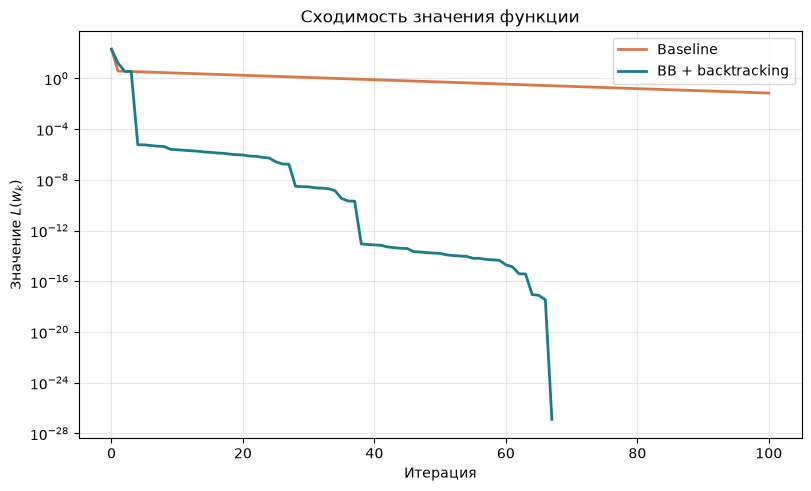

In [5]:
print(
    f"{'Метод':<18} {'Итерации':>6} {'L(w)':>13} "
    f"{'||grad||':>13} {'||w-w*||':>13}"
)
print("-" * 67)
for method, history in results.items():
    print(
        f"{method:<18} {len(history['step_sizes']):>9d} "
        f"{history['values'][-1]:>13.3e} "
        f"{history['gradient_norms'][-1]:>13.3e} "
        f"{np.linalg.norm(history['points'][-1] - MINIMUM_POINT):>13.3e}"
    )

plot_objective_history(results, IMAGE_DIR / "objective_history.png")
plt.show()

Baseline выполняет все итераций и остаётся на расстоянии примерно $0.265$ от глобального минимума. 

Barzilai–Borwein + backtracking дошёл до критерия остановки за 67 итераций. 

### Длина шага по итерациям

Слева - размеры шагов обоих методов. Справа отдельно показано, какой шаг предложил BB и какой шаг остался после проверки backtracking.

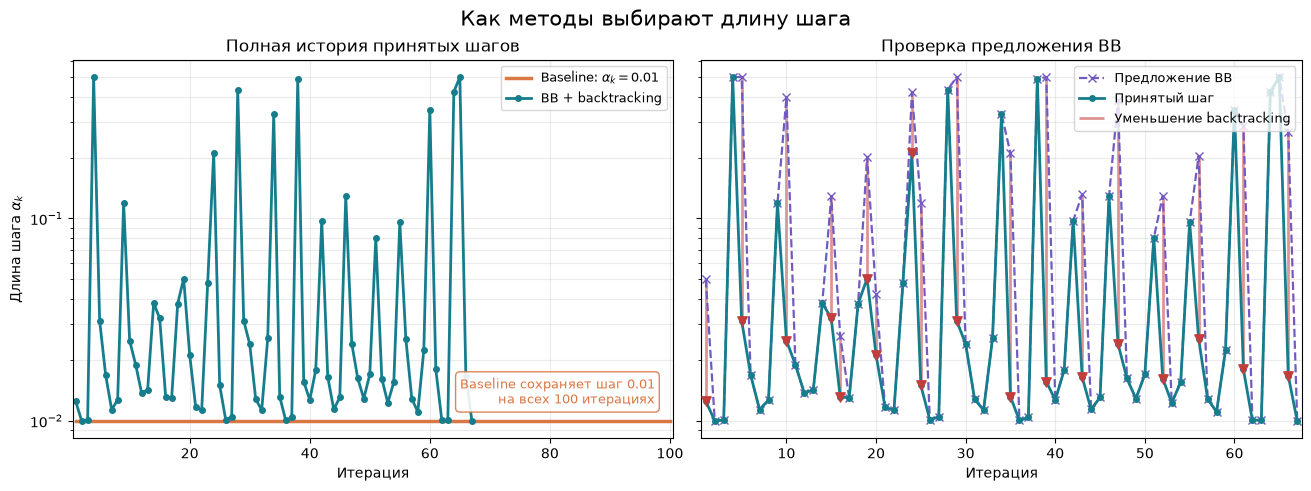

In [6]:
plot_step_history(results, IMAGE_DIR / "step_history.png")
plt.show()

Оптимизированный метод меняет шаг примерно между масштабами обратных собственных значений гессиана — $0.01$ и $0.5$. На правом графике красные вертикальные отрезки показывают, насколько backtracking уменьшил предложение BB; красный треугольник отмечает итоговый принятый шаг.

#### Траектория изменения обоими методами

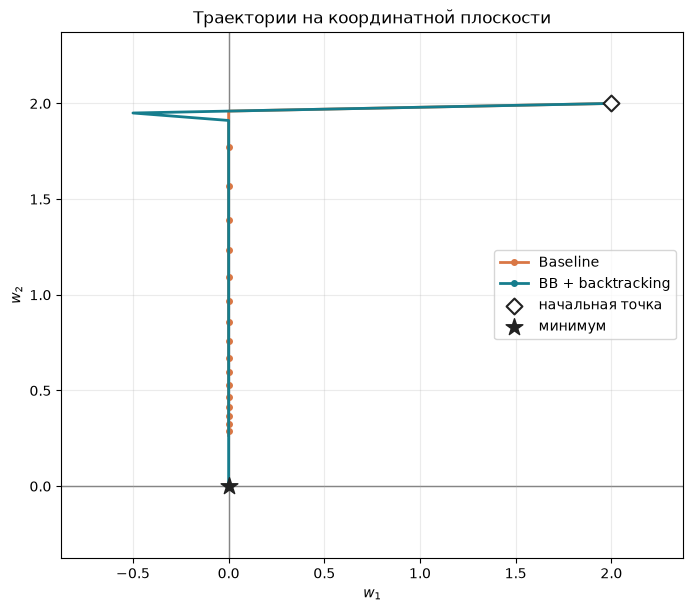

In [7]:
plot_trajectories(results, MINIMUM_POINT, IMAGE_DIR / "trajectories.png")
plt.show()

Baseline первым шагом зануляет $w_1$, но затем медленно спускается вертикально. BB + backtracking немного корректирует первые шаги, а затем быстрее сходится к минимуму.

## Вывод

Проблема baseline — безопасный шаг $0.01$ выбран с учётом самого крутого направления. После того как первая координата почти сразу обнуляется, этот шаг становится слишком малым, и вдоль второй координаты движение идёт медленно. Поэтому метод медленно сходится к оптимуму (но сходится).

У BB + backtracking поведение получается более гибким. BB увеличивает шаг там, где поверхность пологая, а backtracking вмешивается, если такое увеличение оказалось слишком большим (на графике проверка предположения ВВ явно видно). Эти оптимизации уже позволили методу приблизиться к оптимуму за относительно малое колличество шагов.

Но важнее всего, что теперь нам не нужно перебирать и гадать какой learning_rate выбрать, а алгоритм сам может подобрать в зависимости от данных.